Ячейка 1 — заголовок и импорты

In [3]:
# EDA: детекция мошеннических транзакций по банковским картам
# Датасет: Credit Card Fraud Detection (ULB, Kaggle)
# Ссылка на данные: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
# Файл creditcard.csv не хранится в репозитории.
# Скачайте его по ссылке выше и положите рядом с этим ноутбуком.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

df = pd.read_csv("creditcard.csv")

Ячейка 2 — базовые характеристики

In [5]:
print("1. Базовые характеристики датасета")

print("Размер датасета:", df.shape)

df.info()

display(df.describe().T)

print("\nКоличество пропущенных значений по столбцам:")
print(df.isna().sum())

print("\nКоличество дубликатов:", df.duplicated().sum())

print("\nРаспределение классов:")
print(df["Class"].value_counts())

print("\nДоли классов:")
print(df["Class"].value_counts(normalize=True))

1. Базовые характеристики датасета
Размер датасета: (284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



Количество пропущенных значений по столбцам:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Количество дубликатов: 1081

Распределение классов:
Class
0    284315
1       492
Name: count, dtype: int64

Доли классов:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


Ячейка 3 — дисбаланс классов

2. Дисбаланс классов


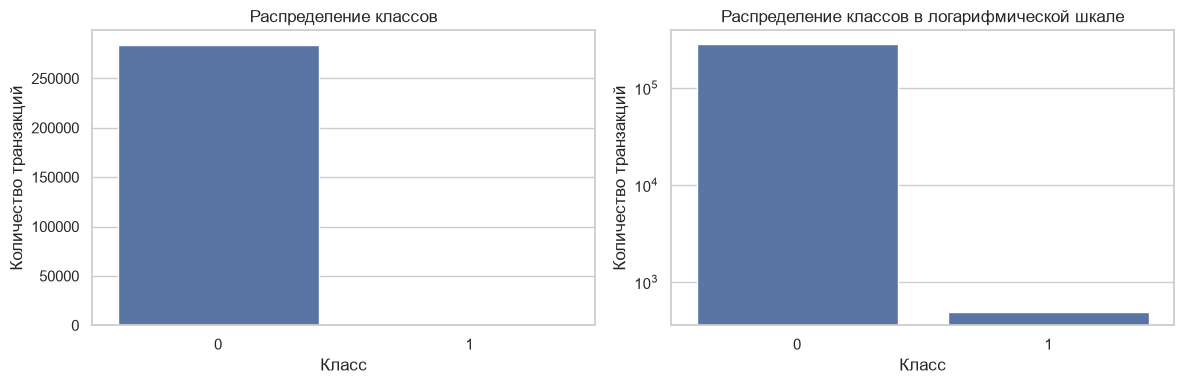

In [6]:
print("2. Дисбаланс классов")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x="Class", data=df, ax=axes[0])
axes[0].set_title("Распределение классов")
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("Количество транзакций")

sns.countplot(x="Class", data=df, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Распределение классов в логарифмической шкале")
axes[1].set_xlabel("Класс")
axes[1].set_ylabel("Количество транзакций")

plt.tight_layout()
plt.show()

Ячейка 4 — сумма транзакции

3. Анализ суммы транзакции


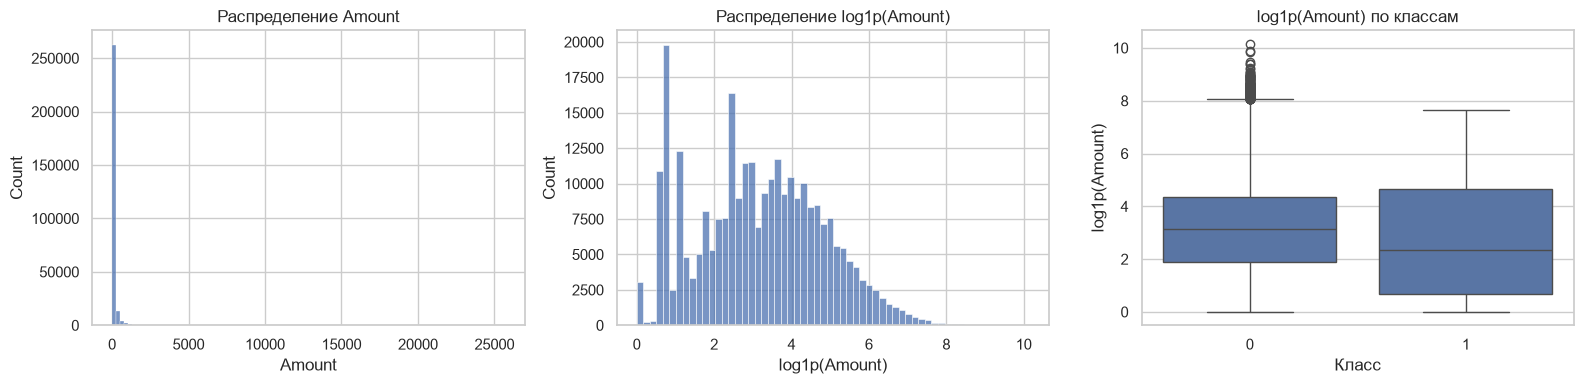

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [7]:
print("3. Анализ суммы транзакции")

df["log_amount"] = np.log1p(df["Amount"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["Amount"], bins=100, ax=axes[0])
axes[0].set_title("Распределение Amount")
axes[0].set_xlabel("Amount")

sns.histplot(df["log_amount"], bins=60, ax=axes[1])
axes[1].set_title("Распределение log1p(Amount)")
axes[1].set_xlabel("log1p(Amount)")

sns.boxplot(x="Class", y="log_amount", data=df, ax=axes[2])
axes[2].set_title("log1p(Amount) по классам")
axes[2].set_xlabel("Класс")
axes[2].set_ylabel("log1p(Amount)")

plt.tight_layout()
plt.show()

display(df.groupby("Class")["Amount"].describe())

Ячейка 5 — время транзакций

4. Анализ времени транзакций


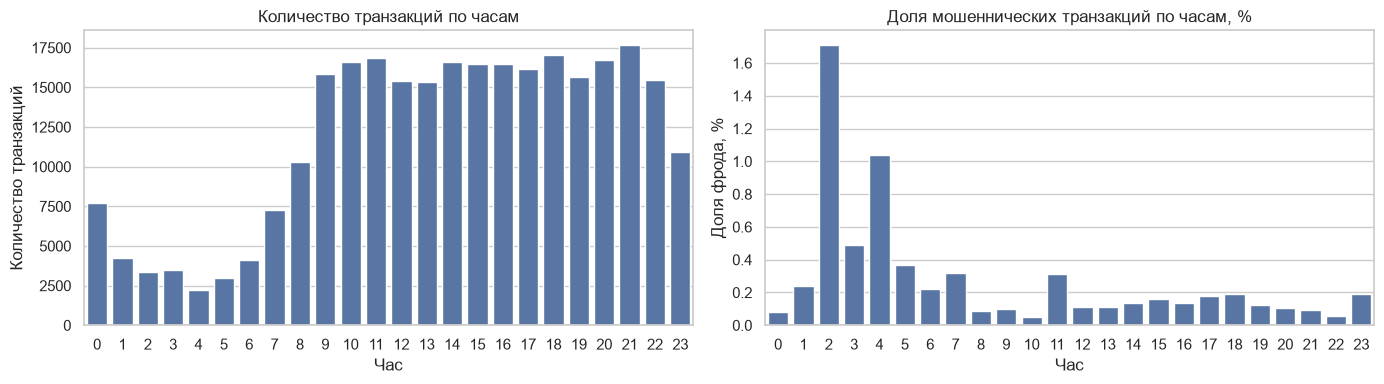

In [14]:
print("4. Анализ времени транзакций")

df["Hour"] = (df["Time"] // 3600 % 24).astype(int)

hourly = df.groupby("Hour")["Class"].agg(
    transactions="count",
    fraud_rate="mean"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(x=hourly.index, y=hourly["transactions"], ax=axes[0])
axes[0].set_title("Количество транзакций по часам")
axes[0].set_xlabel("Час")
axes[0].set_ylabel("Количество транзакций")

sns.barplot(x=hourly.index, y=hourly["fraud_rate"] * 100, ax=axes[1])
axes[1].set_title("Доля мошеннических транзакций по часам, %")
axes[1].set_xlabel("Час")
axes[1].set_ylabel("Доля фрода, %")

plt.tight_layout()
plt.show()

Ячейка 6 — информативность V1–V28

5. Информативность признаков V1–V28
Топ-10 наиболее информативных признаков:
V17    7.861863
V14    7.285436
V12    6.275236
V10    5.222673
V16    4.732777
V3     4.646614
V7     4.509253
V11    3.729500
V4     3.213497
V18    2.684633
dtype: float64


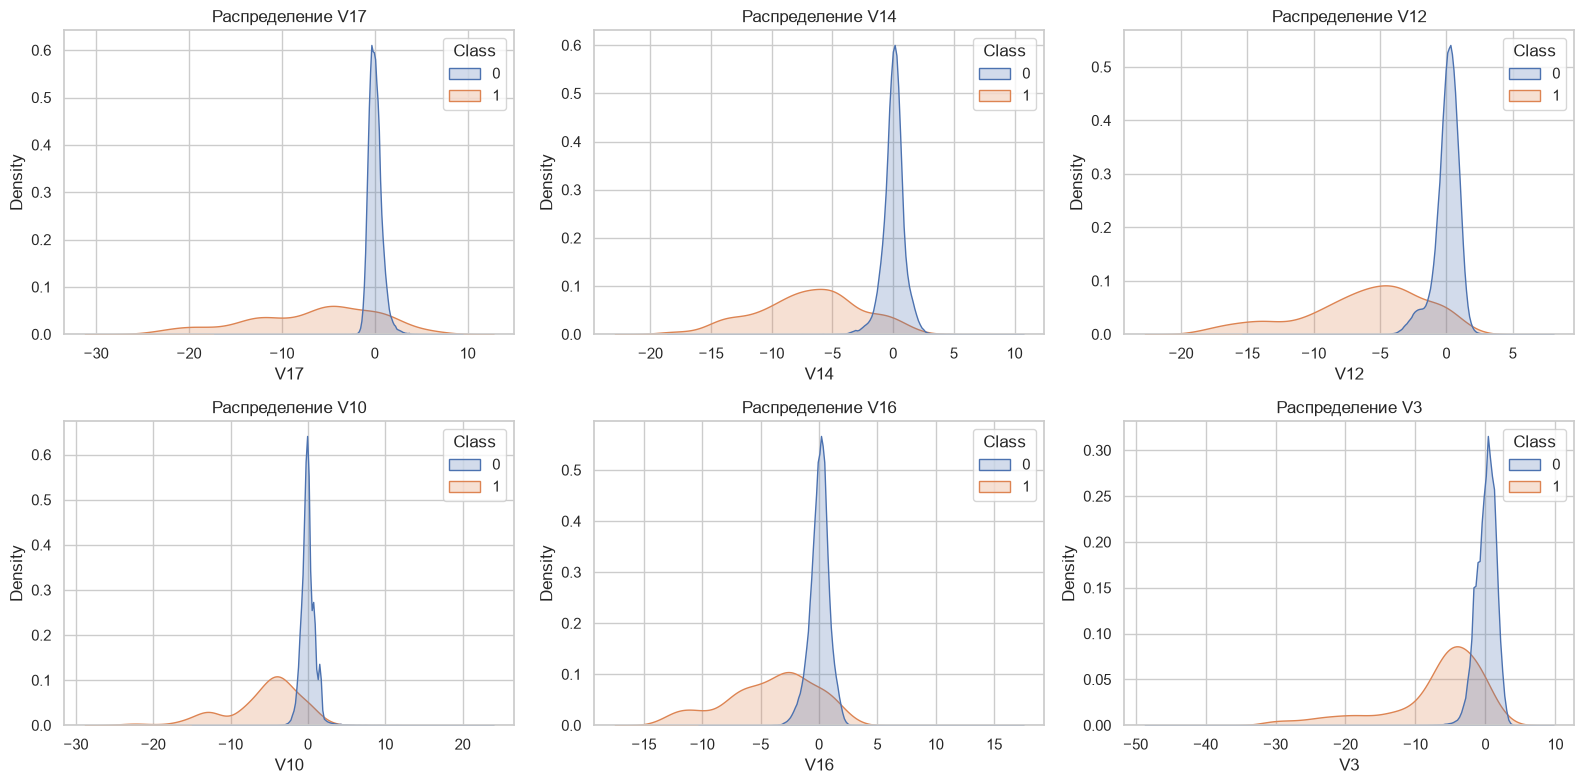

In [13]:
print("5. Информативность признаков V1–V28")


v_features = [f"V{i}" for i in range(1, 29)]

separation = {}

for feature in v_features:
    mean_fraud = df.loc[df["Class"] == 1, feature].mean()
    mean_normal = df.loc[df["Class"] == 0, feature].mean()
    std = df[feature].std()
    separation[feature] = abs(mean_fraud - mean_normal) / std

separation = pd.Series(separation).sort_values(ascending=False)

print("Топ-10 наиболее информативных признаков:")
print(separation.head(10))

top_features = separation.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, feature in zip(axes.ravel(), top_features):
    sns.kdeplot(
        data=df,
        x=feature,
        hue="Class",
        common_norm=False,
        fill=True,
        ax=ax
    )
    ax.set_title(f"Распределение {feature}")

plt.tight_layout()
plt.show()

Ячейка 7 — корреляции

6. Корреляционный анализ


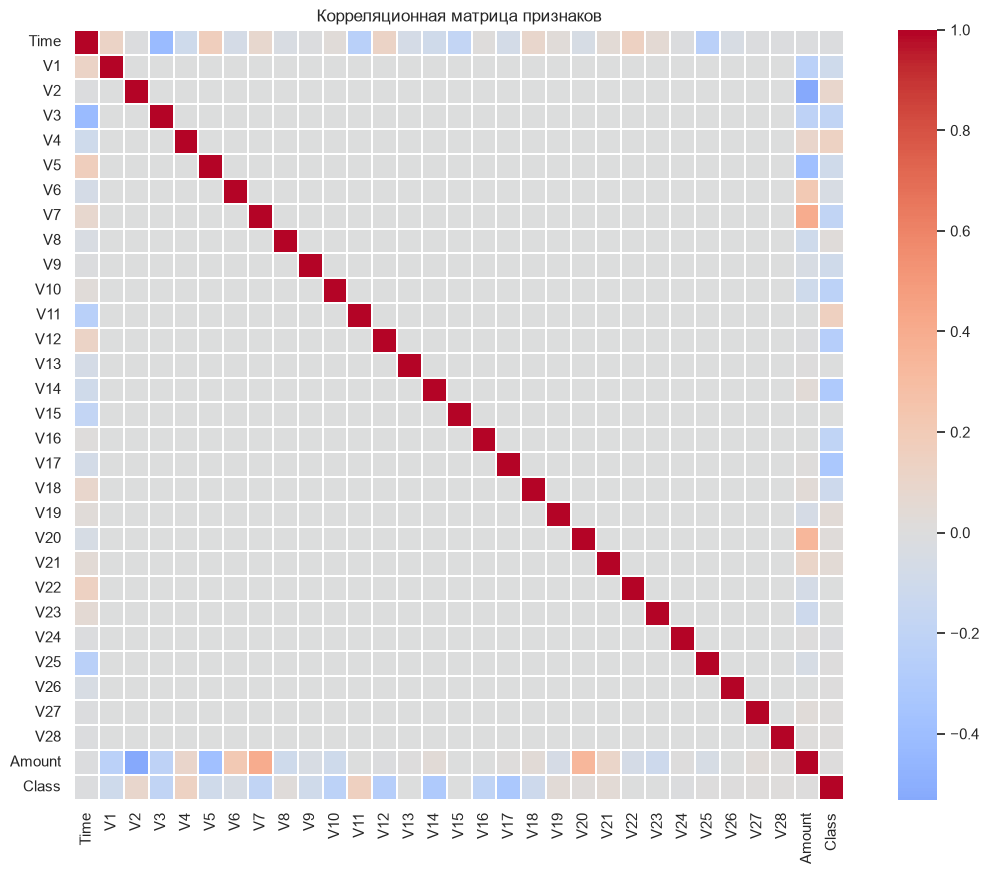

Топ-10 признаков по корреляции с Class:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64


In [15]:
print("6. Корреляционный анализ")

corr = df.drop(columns=["Hour", "log_amount"]).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3
)
plt.title("Корреляционная матрица признаков")
plt.show()

print("Топ-10 признаков по корреляции с Class:")
print(corr["Class"].drop("Class").sort_values(key=abs, ascending=False).head(10))

Ячейка 8 — выбросы

7. Анализ выбросов


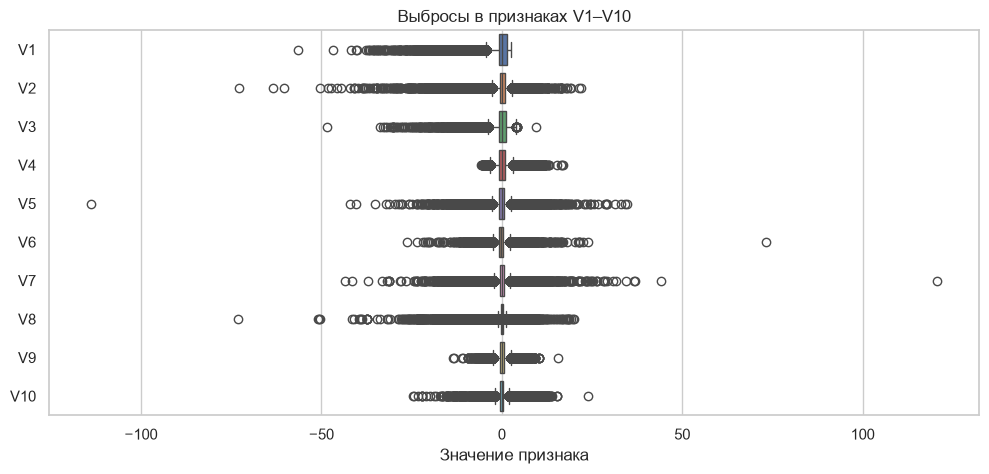

In [17]:
print("7. Анализ выбросов")

plt.figure(figsize=(12, 5))

sns.boxplot(data=df[v_features[:10]], orient="h")
plt.title("Выбросы в признаках V1–V10")
plt.xlabel("Значение признака")
plt.show()

Ячейка 9 — итоговые выводы

In [18]:
print("8. Итоговые выводы EDA")

print("""
1. Датасет имеет экстремальный дисбаланс классов:
   мошеннических транзакций около 0,17%.
2. Основная метрика качества — AUPRC.
   Дополнительные метрики — precision и recall.
   Accuracy неинформативна из-за дисбаланса.
3. Amount имеет скошенное распределение,
   поэтому полезно применить log1p и RobustScaler.
4. Из Time можно извлечь Hour — потенциально полезный признак.
5. V1–V28 почти не коррелируют между собой,
   так как получены методом PCA.
6. Выбросы не удаляем: они могут быть сигналом мошенничества.
7. Для валидации используем стратифицированный
   или временной сплит.
8. Балансировку классов применяем только внутри train,
   но не на test.
""")

8. Итоговые выводы EDA

1. Датасет имеет экстремальный дисбаланс классов:
   мошеннических транзакций около 0,17%.
2. Основная метрика качества — AUPRC.
   Дополнительные метрики — precision и recall.
   Accuracy неинформативна из-за дисбаланса.
3. Amount имеет скошенное распределение,
   поэтому полезно применить log1p и RobustScaler.
4. Из Time можно извлечь Hour — потенциально полезный признак.
5. V1–V28 почти не коррелируют между собой,
   так как получены методом PCA.
6. Выбросы не удаляем: они могут быть сигналом мошенничества.
7. Для валидации используем стратифицированный
   или временной сплит.
8. Балансировку классов применяем только внутри train,
   но не на test.

